# Supplemental Figure 5, Panel C

Scatter plot comparing log2FCs for Dex stimulus vs IFNg stimulus within cREs significantly induced by either stimulus. Elements that significantly gain accessibility with both stimuli are colored black

*Output: PanelC.pdf*

# Setup

In [1]:
# load packages
library(tidyverse)
library(ggrastr)
library(patchwork)
library(RColorBrewer)
library(here)
here::i_am("figures/SuppFig5/PanelC/PanelC.ipynb")
theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)))

sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/SuppFig5/PanelC

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2         RColorBrewer_1.1-3 patchwork_1.3.0    ggrastr_1.0.2     
 [5] lubridate_1.9.4    forcats_1.0.0      stringr_1.5.1      dplyr_1.1.4       
 [9] purrr_1.0.2        readr_2.1.5        tidyr_1.3.1        tibble_3.2.1      
[13] ggplot2_3.5.2      tidyverse_2.0.0   

loaded 

# Load data

In [ ]:
dar_IFN_1h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_IFN_1h.tsv"),
  sep = "\t"
)

dar_IFN_6h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_IFN_6h.tsv"),
  sep = "\t"
)

dar_Dex_1h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_Dex_1h.tsv"),
  sep = "\t"
)

dar_Dex_6h <- read.delim(
  here("inputs", "DARs", "GM12878_stimulus", "DAR_Dex_6h.tsv"),
  sep = "\t"
)


# Statistics

In [3]:
# define sets of IFNg and Dex-inducible genes
IFN_ind <- (dar_IFN_1h$change == "up" |  dar_IFN_6h$change == "up")
Dex_ind <- (dar_Dex_1h$change == "up" |  dar_Dex_6h$change == "up")

# enumerate shared and stimulus-specific gene sets
sum(IFN_ind & Dex_ind)
sum(IFN_ind | Dex_ind)

#correlations between IFNg and Dex log2FCs at 1h and 6h (one sided test for positive correlation)
r_1h <- data.frame(ifn=dar_IFN_1h$logFC, dex=dar_Dex_1h$logFC, ifn_ind=IFN_ind, dex_ind=Dex_ind) %>%
    filter(ifn_ind | dex_ind) %>%
    summarize(est=cor.test(ifn,dex, alternative="greater")$estimate)

r_6h <- data.frame(ifn=dar_IFN_6h$logFC, dex=dar_Dex_6h$logFC, ifn_ind=IFN_ind, dex_ind=Dex_ind) %>%
    filter(ifn_ind | dex_ind) %>%
    summarize(est=cor.test(ifn,dex, alternative="greater")$estimate)

[1] 98

[1] 5821

# Generate plots

In [4]:
p1 <- data.frame(ifn=dar_IFN_6h$logFC, dex=dar_Dex_6h$logFC, ifn_ind=IFN_ind, dex_ind=Dex_ind) %>%
    filter(ifn_ind | dex_ind) %>% 
    ggplot(aes(x=ifn,y=dex)) + 
    geom_hline(yintercept=0) +
    geom_vline(xintercept=0) +
    geom_point(color="grey",size=.5) +
    geom_point(data=data.frame(ifn=dar_IFN_6h$logFC, dex=dar_Dex_6h$logFC, ifn_ind=IFN_ind, dex_ind=Dex_ind) %>% filter(ifn_ind & dex_ind), 
               color="black",size=.5) +
    coord_fixed() +
    ggtitle("t=6h", subtitle=paste("r=",format(r_6h$est, digits=3))) +
    xlab("log2FC accessibility\nIFN vs vehicle") + ylab("log2FC accessibility\nDex vs vehicle") + xlim(-2,4) + ylim(-2,4)

p2 <- data.frame(ifn=dar_IFN_1h$logFC, dex=dar_Dex_1h$logFC, ifn_ind=IFN_ind, dex_ind=Dex_ind) %>%
    filter(ifn_ind | dex_ind) %>% 
    ggplot(aes(x=ifn,y=dex)) + 
    geom_hline(yintercept=0) +
    geom_vline(xintercept=0) +
    geom_point(color="grey",size=.5) +
    geom_point(data=data.frame(ifn=dar_IFN_6h$logFC, dex=dar_Dex_6h$logFC, ifn_ind=IFN_ind, dex_ind=Dex_ind) %>% filter(ifn_ind & dex_ind), 
               color="black",size=.5) +
    coord_fixed() + ggtitle("t=1h", subtitle=paste("r=",format(r_1h$est, digits=3))) +
    xlab("log2FC accessibility\nIFN vs vehicle") + ylab("log2FC accessibility\nDex vs vehicle") + xlim(-2,4) + ylim(-2,4)


# Assemble figure panel

Saving 7 x 7 in image


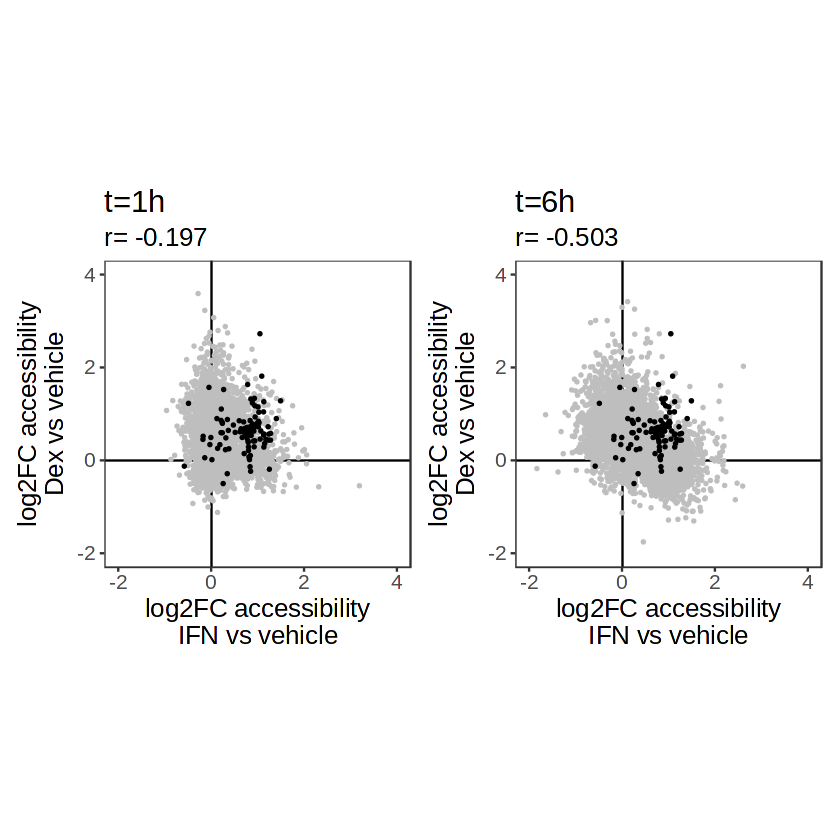

In [5]:
(p2 | p1) + plot_layout(guides="collect")

ggsave("PanelC.pdf")